# Gaussian Process Active Learning + Probly (Experimente A–D)


Datensatz: `make_moons` (binäre, nichtlineare Klassifikation).

Probly wird explizit für die Unsicherheitsquantifizierung verwendet:
1. `GaussianProcessClassifier` liefert die approximierte latente Posterior-Verteilung über `latent_mean_and_variance`.
2. Wir sampeln daraus für jeden Poolpunkt latente Werte und wandeln sie in Klassenwahrscheinlichkeiten um.
3. Diese Wahrscheinlichkeits-Samples werden über Problys öffentliche Factory-Funktionen als Second-Order-Representation übergeben.
4. `probly.quantification.decompose(...)` liefert Total-, aleatorische und epistemische Unsicherheit (EU).

Das ist eine **GP-posteriorbasierte Sample-Representation in Probly**, kein RF-Ensemble und kein direkter Probly-Wrapper für GPC. Die GP-Marginalposterior wird punktweise gesampelt; die Query-Scores sind punktweise Unsicherheiten, dafür ist keine gemeinsame Funktion über alle Poolpunkte erforderlich.

## Experimente

| Experiment | Query-Strategie |
|---|---|
| **A** | Probly-EU × Repräsentativität → Diversity, ab der ersten Runde |
| **B** | Adaptive K-Means → Margin Sampling; Probly-EU steuert den Wechsel |
| **C** | K-Means für feste Warm-up-Runden → Probly-EU × Repräsentativität → Diversity |
| **D** | Adaptive K-Means → Probly-EU × Repräsentativität → Diversity; EU steuert den Wechsel |

Repräsentativität = mittlere RBF-Kernel-Ähnlichkeit zum aktuellen unlabeled Pool.  
Diversity = K-Means auf den Top-Kandidaten, danach Auswahl echter Poolpunkte nahe der Zentren.  
Margin = kleine Differenz zwischen den zwei höchsten Klassenwahrscheinlichkeiten.

Die adaptive Schwelle ist ein Startwert: EU < 80 % der initialen EU für 2 Checks in Folge. Alle Strategien verwenden dasselbe initiale Label-Set und dieselbe Anzahl neu gelabelter Punkte.

In [1]:
%pip install -q "probly>=0.9.1" "scikit-learn>=1.7" numpy scipy matplotlib pandas


Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process.kernels import RBF, ConstantKernel
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss

# Probly public representation factories (compatible across backend layouts)
from probly.representation.distribution import create_categorical_distribution
from probly.representation.sample import create_sample
from probly.quantification import decompose

SEED = 21
N_SAMPLES = 420
MOON_NOISE = 0.25
INITIAL_LABELS = 12
BATCH_SIZE = 6
N_ROUNDS = 12
N_GP_SAMPLES = 64
N_REPEATS = 3
EU_RELATIVE_THRESHOLD = 0.20
EU_PATIENCE = 2
FIXED_KMEANS_WARMUP = 3

print("Imports bereit. Probly decomposes die GP-posterior probability samples.")


Imports bereit. Probly decomposes die GP-posterior probability samples.


In [3]:
def make_dataset(seed):
    X, y = make_moons(n_samples=N_SAMPLES, noise=MOON_NOISE, random_state=seed)
    X_pool, X_test, y_pool, y_test = train_test_split(
        X, y, test_size=0.25, stratify=y, random_state=seed
    )
    scaler = StandardScaler()
    X_pool = scaler.fit_transform(X_pool)
    X_test = scaler.transform(X_test)
    return X_pool, X_test, y_pool, y_test

def make_gpc(seed):
    # Fixierter RBF-Kernel reduziert Rechenzeit und hält Fits vergleichbarer.
    # Für ein Folgeexperiment können Optimierung und Restarts aktiviert werden.
    kernel = ConstantKernel(1.0, constant_value_bounds="fixed") * RBF(
        length_scale=1.0, length_scale_bounds="fixed"
    )
    return GaussianProcessClassifier(
        kernel=kernel,
        optimizer=None,
        random_state=seed,
        max_iter_predict=100,
    )

def fit_gpc(X, y, labeled, seed):
    model = make_gpc(seed)
    model.fit(X[labeled], y[labeled])
    return model


In [4]:
def gp_probly_decomposition(model, X, n_samples=N_GP_SAMPLES, seed=SEED):
    """Pointwise GP posterior samples -> Probly second-order categorical sample -> EU/AU/TU."""
    latent_mean, latent_var = model.latent_mean_and_variance(X)
    latent_mean = np.asarray(latent_mean).reshape(-1)
    latent_var = np.asarray(latent_var).reshape(-1).clip(min=1e-12)

    rng = np.random.default_rng(seed)
    # Draw from sklearn GPC's Laplace-approximated latent marginal posterior.
    f_draws = rng.normal(
        loc=latent_mean[None, :],
        scale=np.sqrt(latent_var)[None, :],
        size=(n_samples, len(X)),
    )
    # Logistic link; binary classes are ordered model.classes_.
    p1 = 1.0 / (1.0 + np.exp(-np.clip(f_draws, -30, 30)))
    prob_samples = np.stack([1.0 - p1, p1], axis=-1)  # (samples, points, classes)

    # Build a Probly second-order sample from first-order categorical distributions.
    # Each row of prob_samples is one posterior draw, shape (points, classes).
    first_order_distributions = [
        create_categorical_distribution(member) for member in prob_samples
    ]
    representation = create_sample(first_order_distributions, sample_axis=0)
    uq = decompose(representation)

    def as_numpy(v):
        if hasattr(v, "detach"):
            v = v.detach().cpu().numpy()
        return np.asarray(v, dtype=float).reshape(-1)

    return as_numpy(uq.epistemic), as_numpy(uq.aleatoric), as_numpy(uq.total), prob_samples

def bvsb_margin(proba):
    p = np.sort(proba, axis=1)
    return 1.0 - (p[:, -1] - p[:, -2])  # higher = more uncertain

def minmax01(a):
    a = np.asarray(a, dtype=float)
    span = a.max() - a.min()
    return (a - a.min()) / span if span > 1e-12 else np.zeros_like(a)

def rbf_representativeness(X_candidates, X_unlabeled, length_scale=1.0):
    sqdist = ((X_candidates[:, None, :] - X_unlabeled[None, :, :])**2).sum(axis=2)
    return np.exp(-sqdist / (2 * length_scale**2)).mean(axis=1)

def diverse_batch(X, candidates, score, batch_size=BATCH_SIZE, top_multiplier=8):
    n_top = min(len(candidates), max(batch_size, top_multiplier * batch_size))
    top = candidates[np.argsort(score)[-n_top:]]
    if len(top) <= batch_size:
        return top.astype(int)

    km = KMeans(n_clusters=batch_size, n_init=10, random_state=SEED)
    km.fit(X[top])
    chosen = []
    for center in km.cluster_centers_:
        order = np.argsort(((X[top] - center)**2).sum(axis=1))
        for j in order:
            idx = int(top[j])
            if idx not in chosen:
                chosen.append(idx)
                break
    return np.asarray(chosen, dtype=int)

def kmeans_batch(X, candidates, batch_size=BATCH_SIZE):
    k = min(batch_size, len(candidates))
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED)
    km.fit(X[candidates])
    chosen = []
    for center in km.cluster_centers_:
        order = np.argsort(((X[candidates] - center)**2).sum(axis=1))
        for j in order:
            idx = int(candidates[j])
            if idx not in chosen:
                chosen.append(idx)
                break
    return np.asarray(chosen, dtype=int)

def ece_score(y_true, proba, n_bins=10):
    confidence = proba.max(axis=1)
    pred = proba.argmax(axis=1)
    correct = (pred == y_true).astype(float)
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    for lo, hi in zip(bins[:-1], bins[1:]):
        mask = (confidence >= lo) & (confidence < hi if hi < 1 else confidence <= hi)
        if mask.any():
            ece += mask.mean() * abs(correct[mask].mean() - confidence[mask].mean())
    return float(ece)

def normalized_aubc(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    return float(np.trapezoid(y, x) / (x[-1] - x[0])) if len(x) > 1 and x[-1] > x[0] else float(y.mean())


## Active-Learning-Loop

Probly-EU wird für:
- A, C und D als Unsicherheitsanteil im Query-Score,
- B und D als adaptive Switch-Metrik,
- alle Strategien zur finalen Unsicherheitsbewertung auf demselben Testset

verwendet. Testlabels fließen ausschließlich in die Evaluation ein.

In [5]:
def run_experiment(strategy, seed):
    X, X_test, y, y_test = make_dataset(seed)
    rng = np.random.default_rng(seed)

    # Stratified initial labels: beide Klassen sind sicher vertreten.
    initial = np.concatenate([
        rng.choice(np.flatnonzero(y == cls), size=INITIAL_LABELS // 2, replace=False)
        for cls in np.unique(y)
    ])
    labeled = list(map(int, initial))
    unlabeled = list(map(int, np.setdiff1d(np.arange(len(X)), initial)))

    # Fixed, label-free monitoring set. EU is computed from X only.
    monitor = np.asarray(unlabeled[:min(100, len(unlabeled))])
    baseline_eu = None
    below_count = 0
    switched = False
    switch_round = None
    rows = []

    for round_idx in range(N_ROUNDS + 1):
        model = fit_gpc(X, y, labeled, seed + round_idx)
        p_test = model.predict_proba(X_test)
        acc = accuracy_score(y_test, p_test.argmax(axis=1))

        eu_monitor, _, _, _ = gp_probly_decomposition(
            model, X[monitor], seed=seed + 500 + round_idx
        )
        mean_eu_monitor = float(eu_monitor.mean())
        if baseline_eu is None:
            baseline_eu = mean_eu_monitor

        if strategy in ("B", "D") and not switched:
            if mean_eu_monitor < baseline_eu * (1.0 - EU_RELATIVE_THRESHOLD):
                below_count += 1
            else:
                below_count = 0
            if below_count >= EU_PATIENCE:
                switched = True
                switch_round = round_idx

        rows.append({
            "experiment": strategy,
            "seed": seed,
            "round": round_idx,
            "n_labeled": len(labeled),
            "accuracy": acc,
            "monitor_probly_eu": mean_eu_monitor,
            "switch_round": switch_round,
            "phase": "post-switch" if switched else "exploration",
        })

        if round_idx == N_ROUNDS or len(unlabeled) == 0:
            break

        candidates = np.asarray(unlabeled)
        X_c = X[candidates]
        p_c = model.predict_proba(X_c)
        eu_c, _, _, _ = gp_probly_decomposition(
            model, X_c, seed=seed + 1000 + round_idx
        )

        if strategy == "A":
            # Probly EU × R → Diversity from the beginning
            rep = rbf_representativeness(X_c, X_c)
            score = minmax01(eu_c) * minmax01(rep)
            selected = diverse_batch(X, candidates, score)

        elif strategy == "B":
            # Adaptive K-Means -> Margin Sampling (Probly EU controls switch)
            if switched:
                margin_score = bvsb_margin(p_c)
                selected = candidates[np.argsort(margin_score)[-BATCH_SIZE:]]
            else:
                selected = kmeans_batch(X, candidates)

        elif strategy == "C":
            # Fixed K-Means warm-up -> Probly EU × R -> Diversity
            if round_idx < FIXED_KMEANS_WARMUP:
                selected = kmeans_batch(X, candidates)
            else:
                rep = rbf_representativeness(X_c, X_c)
                score = minmax01(eu_c) * minmax01(rep)
                selected = diverse_batch(X, candidates, score)

        elif strategy == "D":
            # Adaptive K-Means -> Probly EU × R -> Diversity
            if not switched:
                selected = kmeans_batch(X, candidates)
            else:
                rep = rbf_representativeness(X_c, X_c)
                score = minmax01(eu_c) * minmax01(rep)
                selected = diverse_batch(X, candidates, score)
        else:
            raise ValueError("strategy muss A, B, C oder D sein")

        selected = np.asarray(selected, dtype=int)
        labeled.extend(selected.tolist())
        unlabeled = np.setdiff1d(unlabeled, selected)

    curve = pd.DataFrame(rows)

    final_model = fit_gpc(X, y, labeled, seed + 9999)
    final_proba = final_model.predict_proba(X_test)
    final_eu, final_au, final_tu, _ = gp_probly_decomposition(
        final_model, X_test, seed=seed + 20000
    )
    final_metrics = {
        "experiment": strategy,
        "seed": seed,
        "final_n_labeled": len(labeled),
        "final_accuracy": accuracy_score(y_test, final_proba.argmax(axis=1)),
        "final_log_loss": log_loss(y_test, final_proba, labels=final_model.classes_),
        "final_brier": brier_score_loss(y_test, final_proba[:, 1]),
        "final_ece": ece_score(y_test, final_proba),
        "final_probly_eu": float(final_eu.mean()),
        "final_probly_au": float(final_au.mean()),
        "final_probly_total": float(final_tu.mean()),
        "final_eu_p90": float(np.quantile(final_eu, 0.90)),
        "aubc": normalized_aubc(curve["n_labeled"], curve["accuracy"]),
        "switch_round": switch_round,
    }
    return curve, final_metrics


In [6]:
# Benchmark A–D über mehrere Seeds
curve_frames = []
metric_rows = []

for seed in range(SEED, SEED + N_REPEATS):
    for exp in ["A", "B", "C", "D"]:
        curve, metrics = run_experiment(exp, seed)
        curve_frames.append(curve)
        metric_rows.append(metrics)

curves = pd.concat(curve_frames, ignore_index=True)
metrics = pd.DataFrame(metric_rows)
display(metrics.head())


/var/folders/6p/fr5p250s4cb69gcgwqqdj86w0000gn/T/ipykernel_44652/3026615795.py:11: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  curves = pd.concat(curve_frames, ignore_index=True)


,experiment,seed,final_n_labeled,final_accuracy,final_log_loss,final_brier,final_ece,final_probly_eu,final_probly_au,final_probly_total,final_eu_p90,aubc,switch_round
0,A,21,84,0.866667,0.366862,0.106225,0.111707,0.023277,0.478617,0.501894,0.037419,0.858333,NaN
1,B,21,84,0.914286,0.419343,0.121238,0.224904,0.029078,0.578252,0.607330,0.051157,0.879365,3.0
2,C,21,84,0.876190,0.366045,0.105274,0.100116,0.024330,0.484648,0.508979,0.037740,0.852381,NaN
3,D,21,84,0.876190,0.366045,0.105274,0.100116,0.024330,0.484648,0.508979,0.037740,0.852381,3.0
4,A,22,84,0.885714,0.361658,0.102424,0.135432,0.024578,0.495978,0.520556,0.038041,0.873016,NaN


findfont: Failed to find font weight 300 for DejaVu Sans, now using 400.
findfont: Failed to find font weight 600 for DejaVu Sans, now using 700.


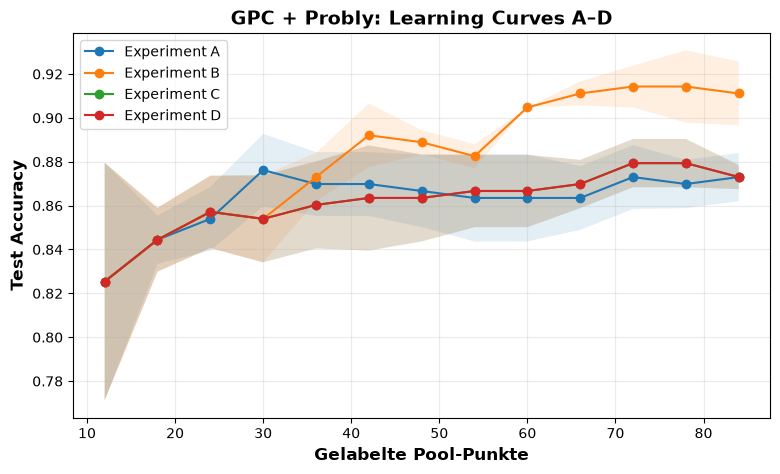

In [7]:
# Learning curves: Mittelwert und Standardabweichung über Seeds
curve_summary = curves.groupby(["experiment", "n_labeled"])["accuracy"].agg(
    mean="mean", std="std"
).reset_index()

fig, ax = plt.subplots(figsize=(9, 5))
for exp, group in curve_summary.groupby("experiment"):
    group = group.sort_values("n_labeled")
    ax.plot(group.n_labeled, group["mean"], marker="o", label=f"Experiment {exp}")
    sd = group["std"].fillna(0)
    ax.fill_between(group.n_labeled, group["mean"] - sd, group["mean"] + sd, alpha=0.12)
ax.set_xlabel("Gelabelte Pool-Punkte")
ax.set_ylabel("Test Accuracy")
ax.set_title("GPC + Probly: Learning Curves A–D")
ax.grid(alpha=0.25)
ax.legend()
plt.show()


## Finale Rangfolge: Performance und Unsicherheit getrennt

- **Accuracy-Gewinner:** höchste mittlere finale Test-Accuracy (Tie-Breaker AUBC).
- **AUBC-Gewinner:** beste mittlere Learning Curve.
- **Am unsichersten:** höchste mittlere finale Probly-EU auf demselben Testset und Label-Budget.

Die EU ist die von Probly quantifizierte epistemische Unsicherheit des GP-Sample-Posteriors. Hohe EU heißt nicht automatisch niedrige Accuracy; deshalb berichten wir beide separat.

In [8]:
ranking = metrics.groupby("experiment").agg(
    accuracy_mean=("final_accuracy", "mean"),
    accuracy_sd=("final_accuracy", "std"),
    AUBC_mean=("aubc", "mean"),
    ECE_mean=("final_ece", "mean"),
    LogLoss_mean=("final_log_loss", "mean"),
    Probly_EU_mean=("final_probly_eu", "mean"),
    Probly_EU_sd=("final_probly_eu", "std"),
    Probly_AU_mean=("final_probly_au", "mean"),
    Probly_total_mean=("final_probly_total", "mean"),
    Switch_round_mean=("switch_round", "mean"),
).sort_values(["accuracy_mean", "AUBC_mean"], ascending=False)

display(ranking.round(4))

best_accuracy = ranking.index[0]
best_aubc = ranking["AUBC_mean"].idxmax()
most_uncertain = ranking["Probly_EU_mean"].idxmax()

print(f"Beste finale Accuracy: Experiment {best_accuracy}")
print(f"Bester AUBC: Experiment {best_aubc}")
print(f"Höchste finale Probly-EU: Experiment {most_uncertain}")


,accuracy_mean,accuracy_sd,AUBC_mean,ECE_mean,LogLoss_mean,Probly_EU_mean,Probly_EU_sd,Probly_AU_mean,Probly_total_mean,Switch_round_mean
experiment,,,,,,,,,,
B,0.9111,0.0145,0.8837,0.2260,0.4111,0.0295,0.0011,0.5746,0.6041,3.0
A,0.8730,0.0110,0.8636,0.1168,0.3643,0.0239,0.0007,0.4830,0.5069,NaN
C,0.8730,0.0055,0.8628,0.1075,0.3685,0.0246,0.0007,0.4896,0.5142,NaN
D,0.8730,0.0055,0.8628,0.1075,0.3685,0.0246,0.0007,0.4896,0.5142,3.0


Beste finale Accuracy: Experiment B
Bester AUBC: Experiment B
Höchste finale Probly-EU: Experiment B


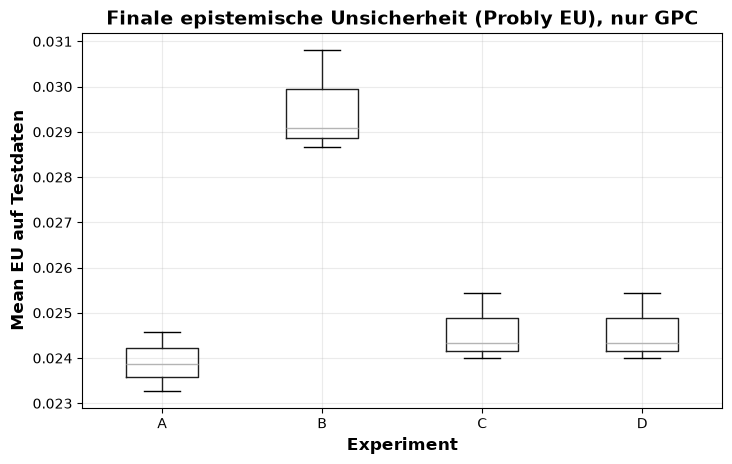

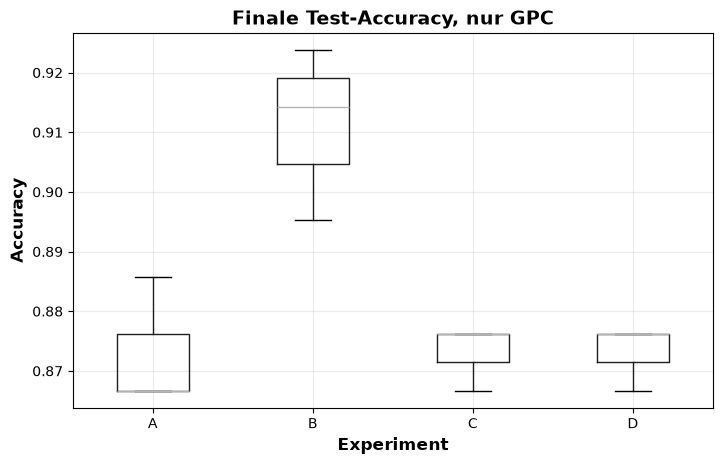

In [9]:
# Unsicherheit und Genauigkeit über Wiederholungen visualisieren
fig, ax = plt.subplots(figsize=(8, 5))
metrics.boxplot(column="final_probly_eu", by="experiment", ax=ax)
ax.set_title("Finale epistemische Unsicherheit (Probly EU), nur GPC")
fig.suptitle("")
ax.set_xlabel("Experiment")
ax.set_ylabel("Mean EU auf Testdaten")
ax.grid(alpha=0.25)
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
metrics.boxplot(column="final_accuracy", by="experiment", ax=ax)
ax.set_title("Finale Test-Accuracy, nur GPC")
fig.suptitle("")
ax.set_xlabel("Experiment")
ax.set_ylabel("Accuracy")
ax.grid(alpha=0.25)
plt.show()


## Hinweise zur Interpretation und Reproduzierbarkeit

- In allen vier Experimenten ist der Learner **GaussianProcessClassifier**. Es wird kein RF verwendet.
- sklearn-GPC verwendet eine Laplace-Approximation und stellt für binäre Klassifikation `latent_mean_and_variance` bereit. Daraus sampeln wir latente Marginalwerte; der Logit-Link ergibt die Probly-Wahrscheinlichkeits-Samples.
- Diese punktweisen Samples approximieren die GP-Posteriorunsicherheit pro Poolpunkt. Sie sind keine kohärenten gemeinsamen GP-Funktionssamples über alle x.
- Der Kernel ist in diesem ersten Benchmark fixiert, damit die Fits schneller und zwischen Iterationen stabiler sind. Für eine spätere Studie kann man Hyperparameteroptimierung aktivieren.
- Probly-EU auf dem Testset wird nur zur abschließenden Auswertung berechnet. Das adaptive Switch-Kriterium nutzt ausschließlich einen festen, unlabeled Monitoring-Pool.
- Mehr Seeds und Sensitivität von Noise, EU-Schwelle, Patience und Batchgröße sind für belastbare Aussagen wichtig.
- AUBC wird über die Labelzahl normalisiert; höher ist besser.